In [204]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
from pathlib import Path

src_path = Path().resolve().parents[1] / 'src'
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))


from sciezka_projektu import get_project_root

PROJECT_ROOT = get_project_root()

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "Ruda Śląska"

df_rs_scada_weteran = pd.read_parquet(DATA_PATH / "scada-weteranow.parquet")
display(df_rs_scada_weteran)

df_rs_scada_zmp = pd.read_parquet(DATA_PATH / "scada-zmp.parquet")
display(df_rs_scada_zmp)

df_rs_opady = pd.read_parquet(DATA_PATH / "suma_opadow.parquet")
display(df_rs_opady)


,Stempel,DataCzas,PoziomSciekow,PrzeplywSciekow,PradP1,PradP2,LicznikSciekow,IloscZalaczenP1,IloscZalaczenP2,CzasPracyP1,CzasPracyP2,PoziomMin,PoziomMax,PoziomOn,PoziomOff
0,1433288,2024-01-01 00:00:10,108,0,0,0,"599179,1",0,1,10722,10684,0,170,150,90
1,1433289,2024-01-01 00:00:30,112,0,0,0,"599179,1",0,1,10722,10684,0,170,150,90
2,1433290,2024-01-01 00:00:50,115,0,0,0,"599179,1",0,1,10722,10684,0,170,150,90
3,1433291,2024-01-01 00:01:10,115,0,0,0,"599179,1",0,1,10722,10684,0,170,150,90
4,1433292,2024-01-01 00:01:30,118,0,0,0,"599179,1",0,1,10722,10684,0,170,150,90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4317920,5751208,2026-09-30 23:58:44,132,0,0,0,"815007,5",1,1,15850,15801,0,170,150,90
4317921,5751209,2026-09-30 23:59:04,132,0,0,0,"815007,5",1,1,15850,15801,0,170,150,90
4317922,5751210,2026-09-30 23:59:24,133,0,0,0,"815007,5",1,1,15850,15801,0,170,150,90
4317923,5751211,2026-09-30 23:59:44,134,0,0,0,"815007,5",1,1,15850,15801,0,170,150,90


,Stempel,DataCzas,PoziomSciekow,PrzeplywSciekow,PradP1,PradP2,LicznikSciekow,IloscZalaczenP1,IloscZalaczenP2,CzasPracyP1,CzasPracyP2,PoziomMin,PoziomMax,PoziomOn,PoziomOff
0,1433263,2024-01-01 00:00:10,90,0,0,0,28,2,3,1112,1134,0,170,145,50
1,1433264,2024-01-01 00:00:30,95,0,0,0,28,2,3,1112,1134,0,170,145,50
2,1433265,2024-01-01 00:00:50,100,0,0,0,28,2,3,1112,1134,0,170,145,50
3,1433266,2024-01-01 00:01:10,100,0,0,0,28,2,3,1112,1134,0,170,145,50
4,1433267,2024-01-01 00:01:30,104,0,0,0,28,2,3,1112,1134,0,170,145,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4317447,5750710,2026-09-30 23:58:44,111,0,0,0,17,2,3,2402,2435,0,170,145,65
4317448,5750711,2026-09-30 23:59:04,111,0,0,0,17,2,3,2402,2435,0,170,145,65
4317449,5750712,2026-09-30 23:59:24,116,0,0,0,17,2,3,2402,2435,0,170,145,65
4317450,5750713,2026-09-30 23:59:44,118,0,0,0,17,2,3,2402,2435,0,170,145,65


,Data_czas,suma_opadu_mm
0,2024-01-01 00:00:00,0.0
1,2024-01-01 01:00:00,0.0
2,2024-01-01 02:00:00,0.0
3,2024-01-01 03:00:00,0.0
4,2024-01-01 04:00:00,0.0
...,...,...
24667,2026-10-24 20:00:00,0.0
24668,2026-10-24 21:00:00,0.0
24669,2026-10-24 22:00:00,0.0
24670,2026-10-24 23:00:00,0.0


In [205]:



from scada_prepare_data import load_scada_weterani


df_weteranow,df_zmp = load_scada()



df_rs_opady["Data_czas"] = pd.to_datetime(df_rs_opady["Data_czas"])
df_rs_opady = df_rs_opady.set_index("Data_czas").sort_index()

df_rs_opady = df_rs_opady.groupby(level=0).agg({"suma_opadu_mm": "sum"})

df_lgbm = df_weteranow.join(df_rs_opady[["suma_opadu_mm"]], how="left")

# Dajemy modelowi kontekst kalendarzowy, ponieważ może zależeć od pory dnia i dnia tygodnia
df_lgbm["hour"] = df_lgbm.index.hour
df_lgbm["dayofweek"] = df_lgbm.index.day_of_week
df_lgbm["month"] = df_lgbm.index.month
df_lgbm["weekend"] = (df_lgbm.index.day_of_week >= 5).astype(int)

#Żeby mieć cykliczność opadów
df_lgbm["hour_sin"] = np.sin(2 * np.pi * df_lgbm.index.hour / 24)
df_lgbm["hour_cos"] = np.cos(2 * np.pi * df_lgbm.index.hour / 24)

# Cykliczność roku
df_lgbm["month_sin"] = np.sin(2 * np.pi * (df_lgbm.index.month - 1) / 12)
df_lgbm["month_cos"] = np.cos(2 * np.pi * (df_lgbm.index.month - 1) / 12)

r = df_lgbm["suma_opadu_mm"]

df_lgbm["opad_lag_1h"] = r.shift(1)
df_lgbm["opad_max6h"] = r.rolling(6).max()


df_lgbm["opad_0h"] = r  # bieżąca godzina
#suma opadów z 2/3/6h itd
for k in [2, 3, 6, 12, 24, 48]:                                             #JAK DALEKO W TYŁ MODEL MA PATRZEĆ NA OPADY (godziny)
    df_lgbm[f"opad_{k}h"] = r.rolling(k).sum()

df_lgbm["opad_max3h"] = r.rolling(3).max()  # intensywność szczytowa

last_rain = df_lgbm.index.to_series().where(r > 0.1).ffill()
df_lgbm["h_od_deszczu"] = ((df_lgbm.index.to_series() - last_rain)
                           .dt.total_seconds() / 3600).clip(upper=240)

#opóźnienia opadów - czy może przepompownia reaguje na opady z opóźnieniem
for k in [2, 3, 6, 12, 24, 48]:
    df_lgbm[f"opad_lag_{k}h"] = r.shift(k)


features = [
    # Kalendarzowe
    "hour", "dayofweek", "month", "weekend",
    "month_sin", "month_cos",

    # Opady
    "opad_0h", "opad_2h", "opad_3h", "opad_6h",
    "opad_12h", "opad_24h", "opad_48h",
    "opad_max6h",

    # Opóźnienia opadów
    "opad_lag_1h", "opad_lag_2h",
    "opad_lag_3h", "opad_lag_6h",
    "opad_lag_12h", "opad_lag_24h"
]


X = df_lgbm[features].copy()
y = df_lgbm["przepompowano"].copy()
# Usuwamy tylko wiersze z brakującą wartością docelową
mask = y.notna()

X = X.loc[mask].copy()
y = y.loc[mask].copy()


In [207]:
display(df_weteranow)

,przepompowano
Data_czas,
2024-01-01 00:00:00,13.5
2024-01-01 01:00:00,13.5
2024-01-01 02:00:00,11.7
2024-01-01 03:00:00,6.8
2024-01-01 04:00:00,11.6
...,...
2026-09-30 20:00:00,6.6
2026-09-30 21:00:00,10.3
2026-09-30 22:00:00,7.0


In [208]:
%load_ext autoreload
%autoreload 2

train_end = int(len(X) * 0.7)

X_train = X.iloc[:train_end]
X_test = X.iloc[train_end:]

y_train = y.iloc[:train_end]
y_test = y.iloc[train_end:]

#print("TRAIN:", X_train.shape, X_train.index.min(), X_train.index.max())
#print("VAL:", X_val.shape, X_val.index.min(), X_val.index.max())
#print("TEST:", X_test.shape, X_test.index.min(), X_test.index.max())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [209]:
# CATBOOST
from catboost import CatBoostRegressor

cb_median = CatBoostRegressor(
    loss_function = "MAE",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_median.fit(X_train, y_train)

cb_q97 = CatBoostRegressor(
    loss_function = "Quantile:alpha=0.97",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_q97.fit(X_train, y_train)

y_pred_val = cb_median.predict(X_test)
q_val = cb_q97.predict(X_test)

Godziny ponad normę: 152 z 7230


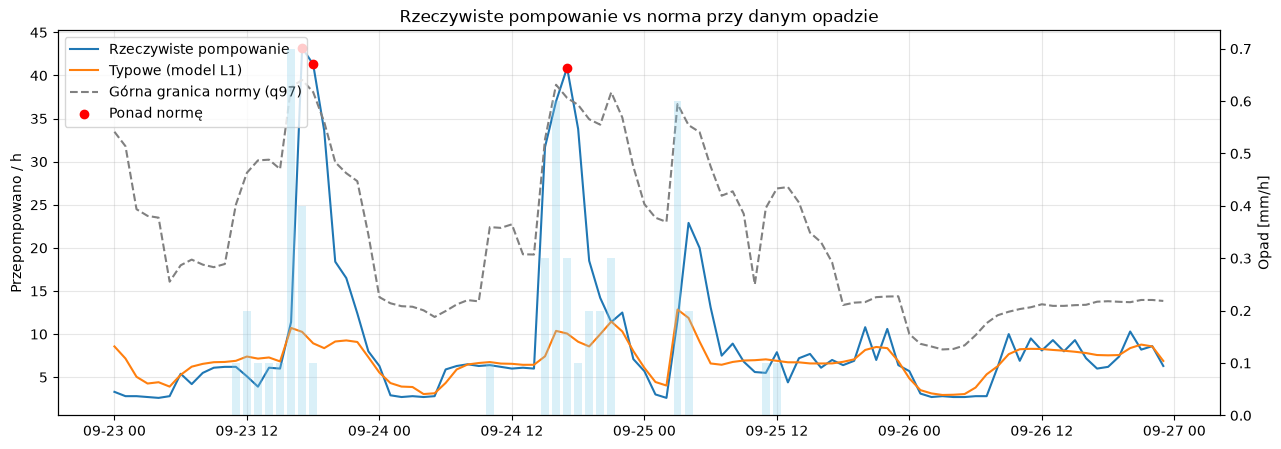

In [210]:
results_val = pd.DataFrame({
    "rzeczywiste": y_test,
    "prognoza": y_pred_val,
    "q97": q_val,
    "opad": X_test["opad_0h"],
    "opad_6h": X_test["opad_6h"],
}, index=y_test.index)

results_val["anomaly"] = results_val["rzeczywiste"] > results_val["q97"]
results_val["ponad_q97"] = (results_val["rzeczywiste"] - results_val["q97"]).clip(lower=0)

print("Godziny ponad normę:", int(results_val["anomaly"].sum()), "z", len(results_val))

sample = results_val.loc["2026-09-23":"2026-09-26"]
alarms = sample[sample["anomaly"]]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(sample.index, sample["rzeczywiste"], label="Rzeczywiste pompowanie")
ax1.plot(sample.index, sample["prognoza"], label="Typowe (model L1)")
ax1.plot(sample.index, sample["q97"], "--", color="gray", label="Górna granica normy (q97)")
ax1.scatter(alarms.index, alarms["rzeczywiste"], color="red", zorder=3, label="Ponad normę")
ax1.set_ylabel("Przepompowano / h")

ax2 = ax1.twinx()
ax2.bar(sample.index, sample["opad"], width=0.03, alpha=0.3, color="skyblue", label="Opad [mm/h]")
ax2.set_ylabel("Opad [mm/h]")

ax1.set_title("Rzeczywiste pompowanie vs norma przy danym opadzie")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()

In [211]:
# Alarm, gdy rzeczywiste pompowanie przekracza Q97
results_val["alarm"] = results_val["anomaly"]

# Nadwyżka względem typowej prognozy pogodowej
results_val["nadwyzka"] = (
    results_val["rzeczywiste"] - results_val["prognoza"]
).clip(lower=0)

print("Liczba godzin alarmowych:", results_val["alarm"].sum())

print(
    "Suma nadwyżek w godzinach alarmowych:",
    round(results_val.loc[results_val["alarm"], "nadwyzka"].sum(), 2)
)

Liczba godzin alarmowych: 152
Suma nadwyżek w godzinach alarmowych: 3486.33


In [212]:
anomalie = results_val[results_val["alarm"]].copy()

#kiedy wystąpiły alarmy, jaka była nadwyżka i czy padało
display(anomalie[["rzeczywiste", "prognoza", "q97", "nadwyzka", "ponad_q97", "opad", "opad_6h"]])

,rzeczywiste,prognoza,q97,nadwyzka,ponad_q97,opad,opad_6h
Data_czas,,,,,,,
2025-12-07 13:00:00,15.1,10.915177,14.732327,4.184823,0.367673,0.0,0.0
2025-12-11 04:00:00,19.1,5.178296,16.842534,13.921704,2.257466,0.1,0.1
2026-01-10 16:00:00,17.0,9.945672,15.108836,7.054328,1.891164,0.0,0.0
2026-01-26 07:00:00,30.8,10.488903,29.164649,20.311097,1.635351,0.2,0.8
2026-02-07 21:00:00,40.5,14.494717,25.369892,26.005283,15.130108,0.1,0.6
...,...,...,...,...,...,...,...
2026-09-21 18:00:00,39.0,11.104409,35.080623,27.895591,3.919377,0.1,4.1
2026-09-22 16:00:00,40.5,16.390842,39.590134,24.109158,0.909866,0.1,2.0
2026-09-23 17:00:00,43.2,10.257436,39.478996,32.942564,3.721004,0.4,1.6


In [213]:
from sklearn.metrics import mean_absolute_error
# Ewaluacja na zbiorze testowym
y_pred_test = cb_median.predict(X_test)
q_test = cb_q97.predict(X_test)

mae_test = mean_absolute_error(y_test, y_pred_test)
odsetek_test = (y_test > q_test).mean() * 100

print("MAE TEST:", round(mae_test, 2))
prof = y_train.groupby(y_train.index.hour).median()
base_test = prof.reindex(y_test.index.hour).values
print("MAE baseline:", round(mean_absolute_error(y_test, base_test), 2))
print("Przekroczenia Q97 TEST:", round(odsetek_test, 2), "%")
print("Liczba alarmów TEST:", int((y_test > q_test).sum()))


MAE TEST: 2.88
MAE baseline: 2.95
Przekroczenia Q97 TEST: 2.1 %
Liczba alarmów TEST: 152


In [214]:
#SHAP
import os
from SHAP import generate_shap_from_tree

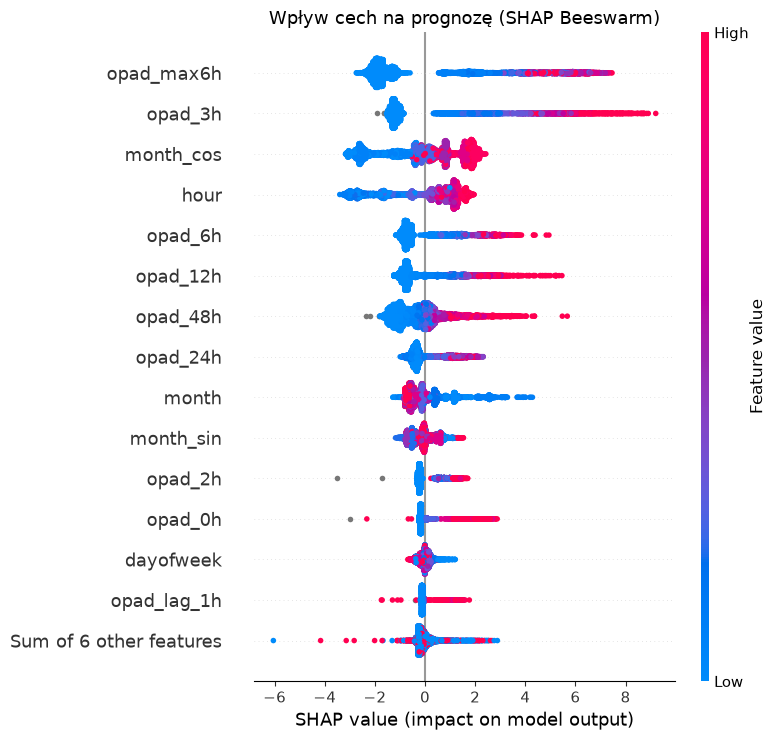

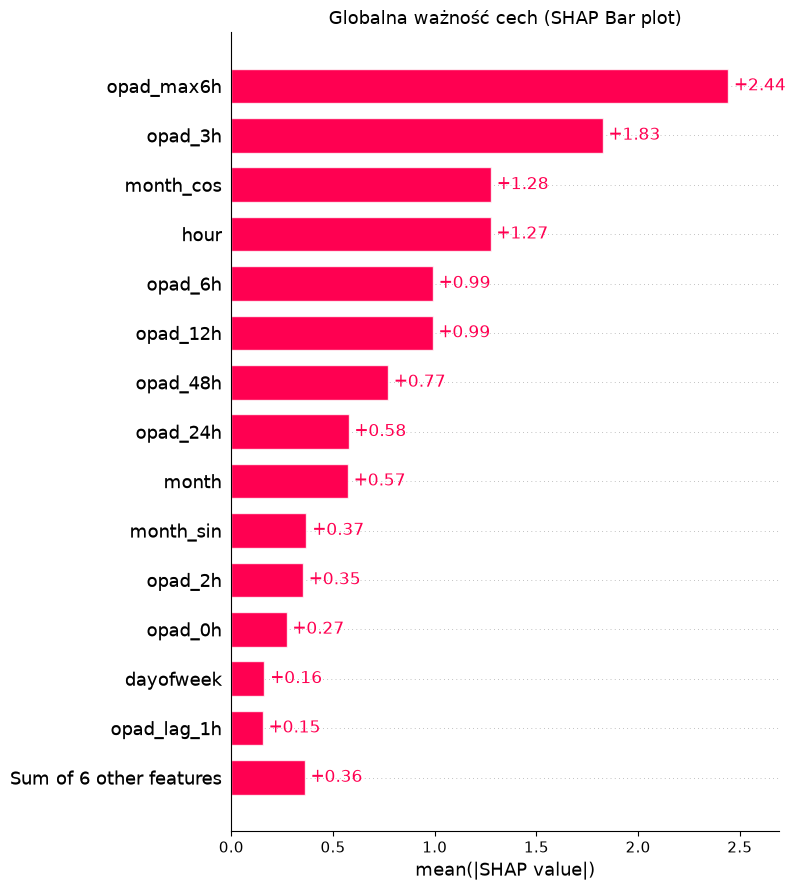

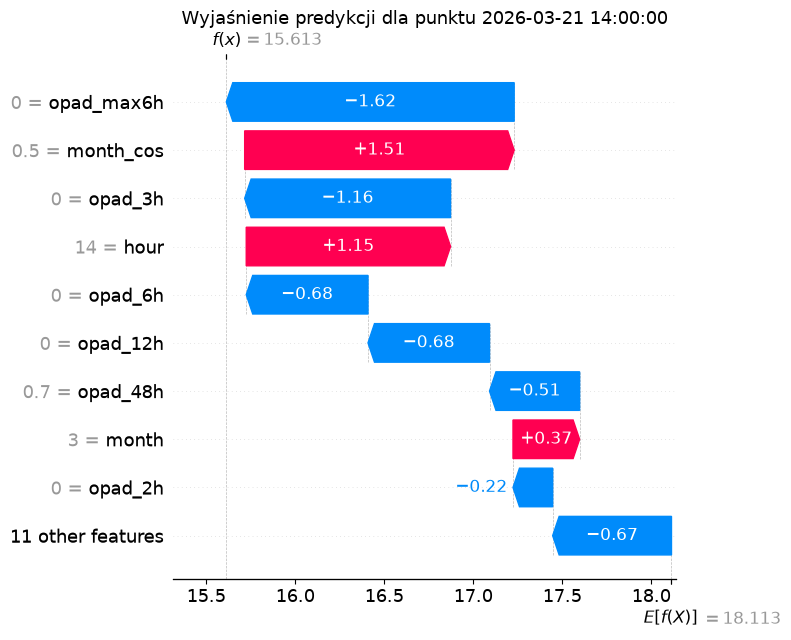

In [215]:
generate_shap_from_tree(cb_q97,X_test,date_with_time="2026-03-21 14:00:00")